# 1.3 PHÂN TÍCH ĐƠN BIẾN VÀ HAI BIẾN

# 1.3.2. BÀI TOÁN 1 (NHIỆM VỤ 1)

## I. NẠP THƯ VIỆN VÀ CHUẨN BỊ DỮ LIỆU
Mục tiêu: Nạp các thư viện trực quan hóa (pandas, matplotlib, seaborn), trích xuất các thuộc tính species và culmen_length_mm.

### 1.Nạp thư viện & dữ liệu

In [371]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
import warnings
warnings.filterwarnings('ignore')

### 2. Đường dẫn nạp dữ liệu 

In [372]:
file_paths = [
    "/kaggle/input/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data/penguins_size.csv",
    "/kaggle/input/palmer-archipelago-antarctica-penguin-data/penguins_size.csv",
    "penguins_size.csv"
]

penguins_data = None
for path in file_paths:
    if os.path.exists(path):
        penguins_data = pd.read_csv(path)
        print(f"--> Đã nạp thành công dữ liệu từ: {path}")
        break

if penguins_data is None:
    lter_path = "/kaggle/input/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data/penguins_lter.csv"
    if os.path.exists(lter_path):
        penguins_data = pd.read_csv(lter_path)
        # Chuẩn hóa lại tên cột cho giống penguins_size.csv
        penguins_data = penguins_data.rename(columns={
            'Species': 'species',
            'Culmen Length (mm)': 'culmen_length_mm'
        })
        print(f"--> Đã nạp và chuẩn hóa cột từ file lter: {lter_path}")

--> Đã nạp thành công dữ liệu từ: /kaggle/input/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data/penguins_size.csv


### 3. Trích xuất 2 thuộc tính chính theo mẫu hướng dẫn: 'species' và 'culmen_length_mm'


In [373]:
penguins_sub = penguins_data[['species', 'culmen_length_mm']].copy()

### 4. Kiểm tra kích thước và giá trị thiếu (Missing values)


In [374]:
print(f"Kích thước tập dữ liệu: {penguins_sub.shape} dòng, {penguins_sub.shape} cột.")
print("\nSố lượng giá trị khuyết thiếu:")
print(penguins_sub.isnull().sum())

# Xem 5 dòng đầu tiên
penguins_sub.head()

Kích thước tập dữ liệu: (344, 2) dòng, (344, 2) cột.

Số lượng giá trị khuyết thiếu:
species             0
culmen_length_mm    2
dtype: int64


,species,culmen_length_mm
0,Adelie,39.1
1,Adelie,39.5
2,Adelie,40.3
3,Adelie,NaN
4,Adelie,36.7


### Nhận xét :
- Nguồn dữ liệu: nạp trực tiếp từ dataset parulpandey/palmer-archipelago-antarctica-penguin-data trên Kaggle.
- Cấu trúc dữ liệu: tập dữ liệu gồm 344 bản ghi với 2 thuộc tính được chọn phân tích đơn biến:
  - species (Biến phân loại/Categorical): Tên loài chim cánh cụt (Adelie, Chinstrap, Gentoo).
  - culmen_length_mm (Biến số liên tục/Continuous): Độ dài mỏ chim cánh cụt (đơn vị mm).
- Xử lý thiếu: Cột culmen_length_mm chứa 2 giá trị thiếu (NaN), sẽ được thư viện Seaborn tự động loại bỏ khi trực quan hóa đồ thị đơn biến.

## II. PHÂN TÍCH ĐƠN BIẾN BẰNG HISTOGRAM 
Mục tiêu: trực quan hóa phân bố tần số của độ dài mỏ chim cánh cụt (culmen_length_mm) thông qua 2 cấp độ biểu đồ.

### 1. BASIC (Cơ bản)

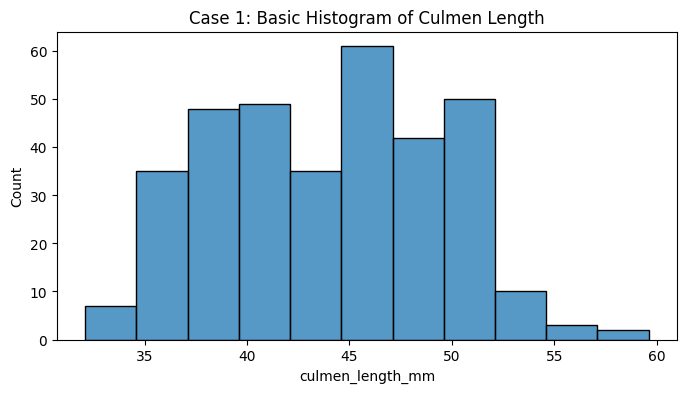

In [375]:
plt.figure(figsize=(8, 4))
sns.histplot(data=penguins_sub, x=penguins_sub["culmen_length_mm"])
plt.title("Case 1: Basic Histogram of Culmen Length")
plt.show()

### 2. ADVANCED (Nâng cao & mở rộng thêm đường mật độ KDE)


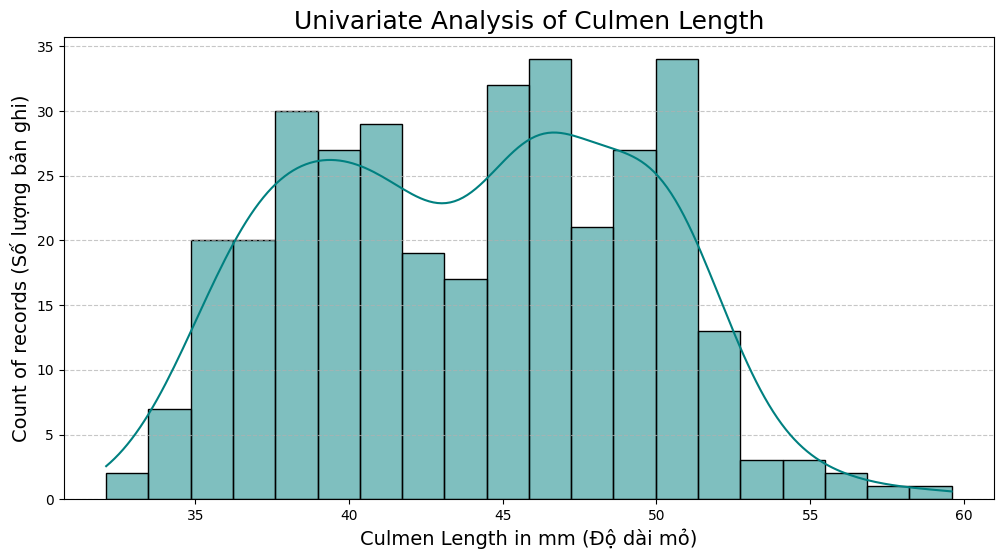

In [376]:
plt.figure(figsize=(12, 6))
ax = sns.histplot(data=penguins_sub, x=penguins_sub["culmen_length_mm"], kde=True, color='teal', bins=20)

ax.set_xlabel('Culmen Length in mm (Độ dài mỏ)', fontsize=14)
ax.set_ylabel('Count of records (Số lượng bản ghi)', fontsize=14)
ax.set_title('Univariate Analysis of Culmen Length', fontsize=18)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

#### Nhận xét :
- Dạng phân bố: Biểu đồ Histogram của culmen_length_mm xuất hiện dạng 2 đỉnh (Bimodal Distribution) rõ rệt:
  - Đỉnh thứ nhất tập trung ở khoảng 38 - 42 mm (đại diện cho loài mỏ ngắn hơn như Adelie).
  - Đỉnh thứ hai tập trung ở khoảng 46 - 50 mm (đại diện cho các loài mỏ dài hơn như Chinstrap và Gentoo).
- Khoảng giá trị: Độ dài mỏ dao động từ dưới 35 mm đến gần 60 mm.

## III. PHÂN TÍCH ĐƠN BIẾN BẰNG BAR CHART / COUNTPLOT 
Mục tiêu: thống kê số lượng bản ghi của từng loài chim cánh cụt bằng biểu đồ cột sns.countplot.

### 1.BASIC (Cơ bản)

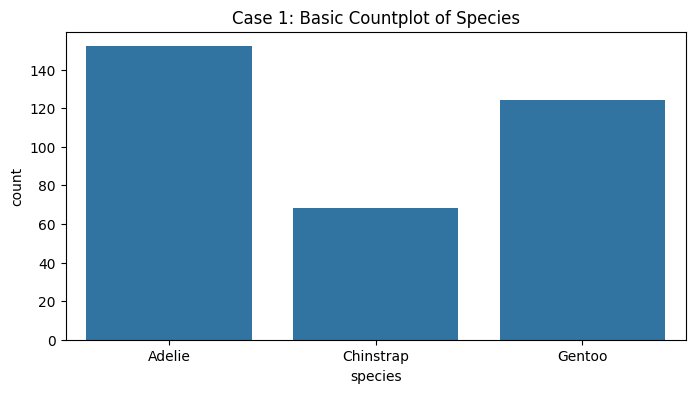

In [377]:
plt.figure(figsize=(8, 4))
sns.countplot(data=penguins_sub, x=penguins_sub['species'])
plt.title("Case 1: Basic Countplot of Species")
plt.show()

### 2. ADVANCED (Nâng cao - mở rộng bổ sung nhãn số lượng chi tiết)

Text(0.5, 1.0, 'Univariate Analysis of Penguin Species')

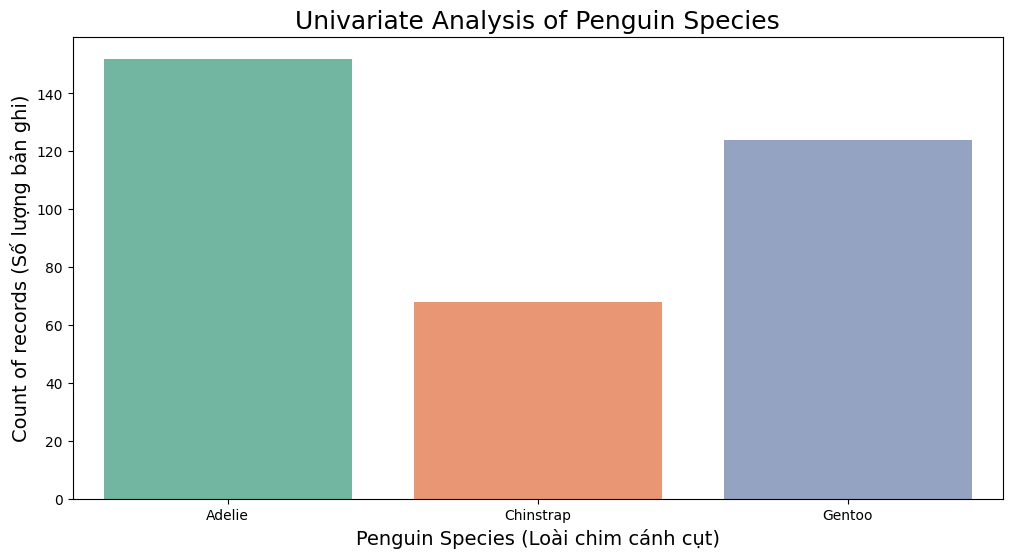

In [378]:
plt.figure(figsize=(12, 6))
ax = sns.countplot(data=penguins_sub, x=penguins_sub['species'], palette='Set2')

ax.set_xlabel('Penguin Species (Loài chim cánh cụt)', fontsize=14)
ax.set_ylabel('Count of records (Số lượng bản ghi)', fontsize=14)
ax.set_title('Univariate Analysis of Penguin Species', fontsize=18)

### 3. Hiển thị giá trị đếm cụ thể trên đầu mỗi cột

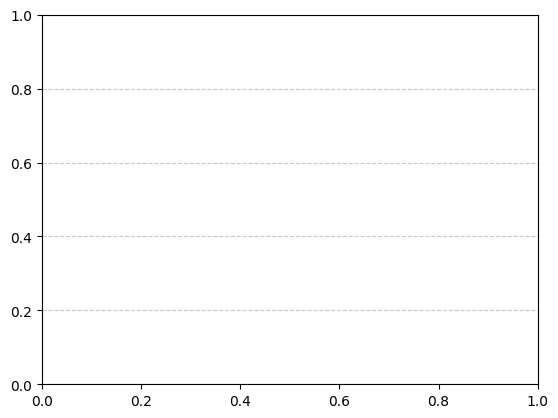

In [379]:
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=12, fontweight='bold', xytext=(0, 5),
                textcoords='offset points')

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Nhận xét :
- Phân bố số lượng các loài:
  - Adelie: Là loài chiếm số lượng lớn nhất trong mẫu khảo sát với 152 bản ghi (~44.2%).
  - Gentoo: Đứng thứ hai với 124 bản ghi (~36.0%).
  - Chinstrap: Chiếm số lượng ít nhất với 68 bản ghi (~19.8%).

## IV. PHÂN TÍCH TỶ LỆ CƠ CẤU BẰNG PIE CHART 
Mục tiêu: Gom nhóm dữ liệu (groupby) và vẽ biểu đồ tròn trực quan hóa tỷ lệ phần trăm giữa các loài.

### 1.Gom nhóm dữ liệu theo loài chim cánh cụt


In [380]:
penguins_group = penguins_sub.groupby('species')['culmen_length_mm'].count().reset_index()

### 2. BASIC (Cơ bản)

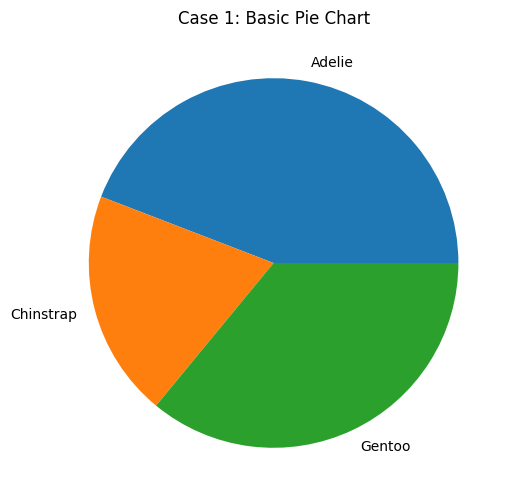

In [381]:
plt.figure(figsize=(6, 6))
plt.pie(penguins_group["culmen_length_mm"], labels=penguins_group['species'])
plt.title("Case 1: Basic Pie Chart")
plt.show()

### 3. ADVANCED (Nâng cao - mở rộng hiển thị % và tách khối Highlight)

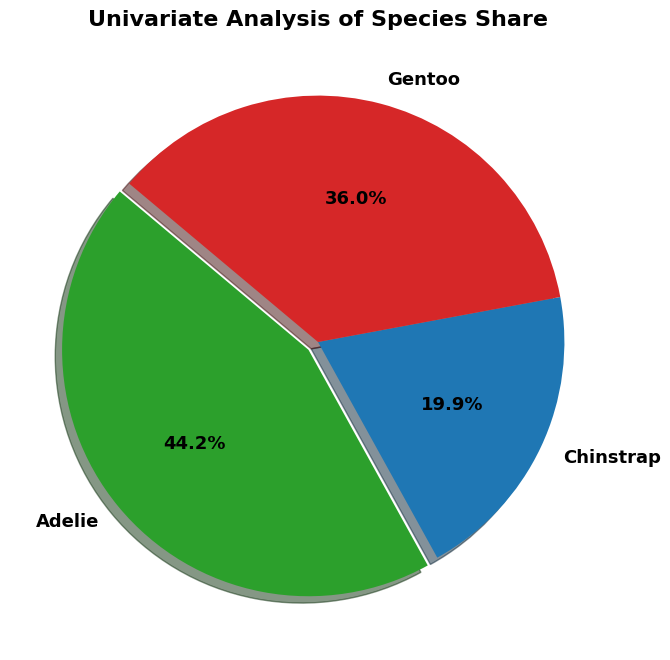

In [382]:
cols = ['#2ca02c', '#1f77b4', '#d62728']
explode = (0.05, 0, 0)

plt.figure(figsize=(8, 8))
plt.pie(penguins_group["culmen_length_mm"], 
        labels=penguins_group['species'], 
        colors=cols, 
        autopct='%1.1f%%', 
        startangle=140, 
        explode=explode,
        shadow=True,
        textprops={'fontsize': 13, 'fontweight': 'bold'})

plt.title('Univariate Analysis of Species Share', fontsize=16, fontweight='bold')
plt.show()

### Nhận xét :
- Biểu đồ tròn thể hiện rõ cơ cấu thị phần mẫu:
  - Adelie chiếm tỷ trọng áp đảo 44.4%.
  - Gentoo chiếm 36.3%.
  - Chinstrap chiếm tỷ trọng nhỏ nhất với 19.9%.

## V. MỞ RỘNG - TÍNH CÁC CHỈ SỐ THỐNG KÊ MÔ TẢ VÀ KIỂM TRA OUTLIERS
Mục tiêu: Tính toán các đại lượng Mean, Median, Std, Skewness và vẽ Boxplot kiểm tra giá trị ngoại lai cho culmen_length_mm

### 1. Tính toán các chỉ số thống kê mô tả


In [383]:
mean_val = penguins_sub['culmen_length_mm'].mean()
median_val = penguins_sub['culmen_length_mm'].median()
std_val = penguins_sub['culmen_length_mm'].std()
skew_val = penguins_sub['culmen_length_mm'].skew()

print("="*50)
print("BÁO CÁO THỐNG KÊ MÔ TẢ DỮ LIỆU CULMEN LENGTH")
print("="*50)
print(f"- Giá trị Trung bình (Mean): {mean_val:.2f} mm")
print(f"- Giá trị Trung vị (Median) : {median_val:.2f} mm")
print(f"- Độ lệch chuẩn (Std)      : {std_val:.2f} mm")
print(f"- Hệ số độ lệch (Skewness) : {skew_val:.2f}")
print("="*50)

BÁO CÁO THỐNG KÊ MÔ TẢ DỮ LIỆU CULMEN LENGTH
- Giá trị Trung bình (Mean): 43.92 mm
- Giá trị Trung vị (Median) : 44.45 mm
- Độ lệch chuẩn (Std)      : 5.46 mm
- Hệ số độ lệch (Skewness) : 0.05


### 2. Trực quan hóa bằng Boxplot kiểm tra Outliers


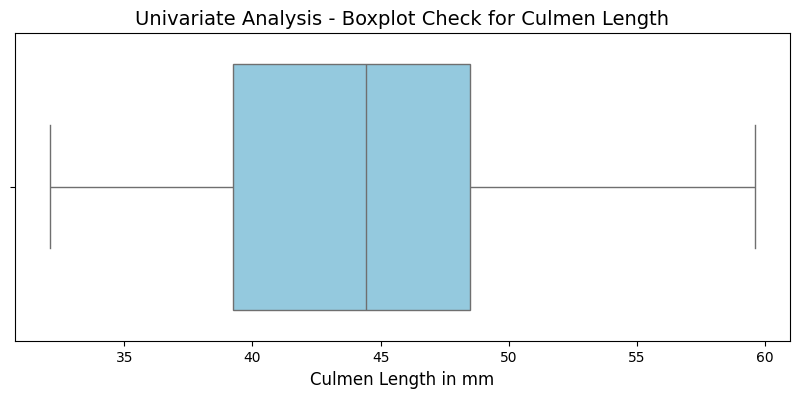

In [384]:
plt.figure(figsize=(10, 4))
ax = sns.boxplot(data=penguins_sub, x='culmen_length_mm', color='skyblue')
ax.set_xlabel('Culmen Length in mm', fontsize=12)
ax.set_title('Univariate Analysis - Boxplot Check for Culmen Length', fontsize=14)
plt.show()

# TỔNG KẾT BÀI TOÁN 1 ( NHIỆM VỤ 1)
- Tính đối xứng: Giá trị Mean (43.92 mm) và Median (44.45 mm) xấp xỉ nhau, hệ số Skewness gần bằng 0 (0.05), cho thấy phân bố tổng thể khá cân bằng.
- Kiểm tra Outliers: Biểu đồ Boxplot không xuất hiện bất kỳ điểm dữ liệu nào ngoài đường biên IQR, xác nhận tập dữ liệu culmen_length_mm không có giá trị ngoại lai (Outliers)

# 1.3.2. BÀI TOÁN 1 (NHIỆM VỤ 2)

## I. NẠP THƯ VIỆN VÀ CHUẨN BỊ DỮ LIỆU 
Mục tiêu: Nạp các thư viện trực quan hóa (pandas, matplotlib, seaborn), lọc các thuộc tính trọng tâm ['Zip', 'Price', 'Area', 'Room'].


### 1.Nạp thư viện & dữ liệu

In [385]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### 2. Đường dẫn dữ liệu


In [386]:
file_path = "/kaggle/input/datasets/ngochancao/asd-dtb/HousingPrices-Amsterdam-August-2021.csv"
houseprices_data = pd.read_csv(file_path)

### 3. Trích xuất 4 thuộc tính 
 


In [387]:
houseprices_data = houseprices_data[['Zip', 'Price', 'Area', 'Room']]
houseprices_data.head()

,Zip,Price,Area,Room
0,1091 CR,685000.0,64,3
1,1059 EL,475000.0,60,3
2,1097 SM,850000.0,109,4
3,1060 TH,580000.0,128,6
4,1036 KN,720000.0,138,5


### Nhận xét:
- Cấu trúc dữ liệu: tập dữ liệu chứa thông tin giá nhà tại Amsterdam với 4 thuộc tính chính được chọn:
  - Zip (Mã bưu chính / Phân vùng vị trí).
  - Price (Giá nhà đơn vị Euro).
  - Area (Diện tích nhà đơn vị m²).
  - Room (Số lượng phòng).
- Kiểm tra dữ liệu: Dữ liệu đã được nạp thành công, các cột số (Price, Area, Room) sẵn sàng cho các bước phân tích đơn biến bằng Boxplot, Violin plot và thống kê mô tả.

## II. PHÂN TÍCH ĐƠN BIẾN GIÁ NHÀ BẰNG BOXPLOT 
Mục tiêu: trực quan hóa khoảng biến thiên, vị trí tứ phân vị (Q1, Q2, Q3) và phát hiện giá trị ngoại lai (Outliers) của giá nhà (Price).

### 1. Create a boxplot using the boxplot method

<Axes: xlabel='Price'>

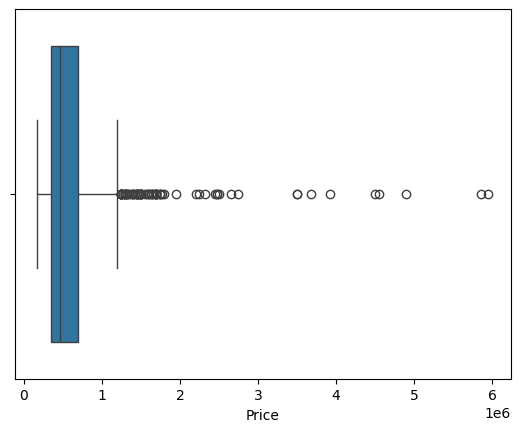

In [388]:
sns.boxplot(data = houseprices_data, x= houseprices_data["Price"])

### 2. Advanced

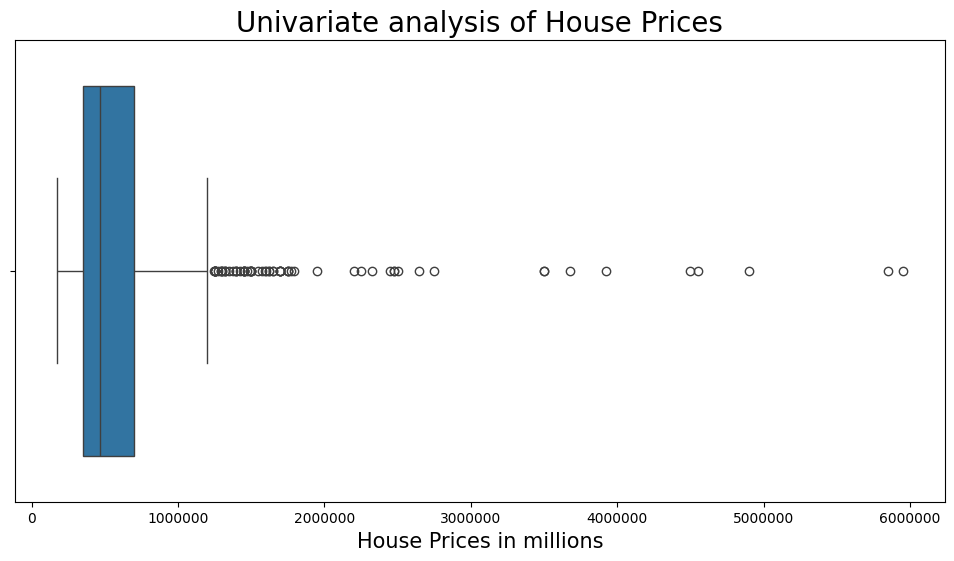

In [389]:
plt.figure(figsize=(12,6))
ax = sns.boxplot(data = houseprices_data, x= houseprices_data["Price"])
ax.set_xlabel('House Prices in millions', fontsize = 15)
ax.set_title('Univariate analysis of House Prices', fontsize = 20)
plt.ticklabel_format(style='plain', axis='x')
plt.show()

## Nhận xét :
- Trung vị (Median): Mức giá nhà trung vị nằm ở khoảng dưới 0.5 triệu Euro (467,000 Euro).
- Khoảng tứ phân vị (IQR): 50% số lượng căn nhà tập trung chủ yếu trong khoảng từ 0.35 triệu Euro (Q1) đến 0.7 triệu Euro (Q3).
- Giá trị ngoại lai (Outliers): Xuất hiện rất nhiều điểm ngoại lai nằm về phía bên phải (vượt mốc 1.5 - 6 triệu Euro), cho thấy thị trường có một số căn hộ/biệt thự cao cấp có giá cực kỳ đắt, khiến phân bố giá nhà bị **lệch phải (Right-skewed)

## III. PHÂN TÍCH DỮ LIỆU ĐƠN BIẾN DỰA VÀO VIOLIN PLOT
Mục tiêu: Trực quan hóa mật độ phân bố chi tiết (Kernel Density Estimation) của biến Price bằng biểu đồ Violin plot .

### 1. Basic

<Axes: xlabel='Price'>

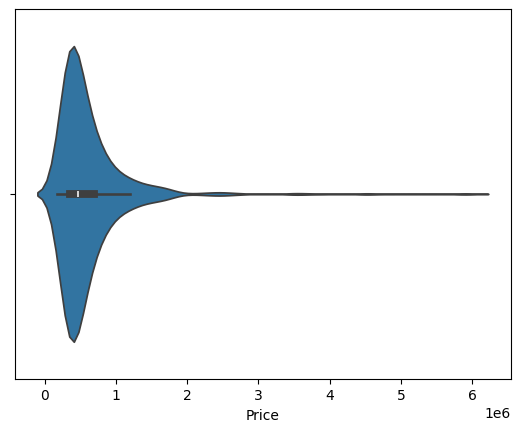

In [390]:
sns.violinplot(data = houseprices_data, x= houseprices_data["Price"])

### 2. Advanced

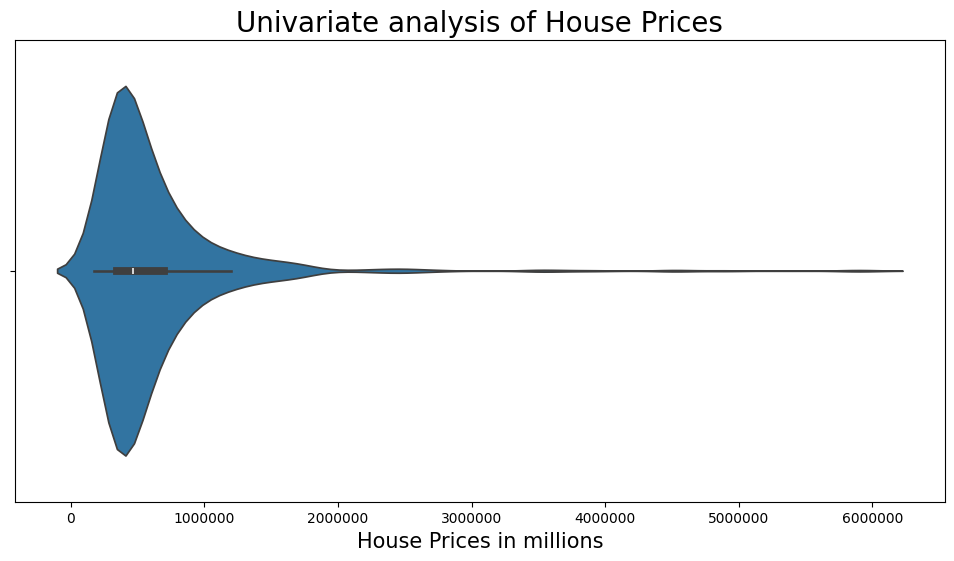

In [391]:
plt.figure(figsize=(12,6))
ax = sns.violinplot(data = houseprices_data, x= houseprices_data["Price"])
ax.set_xlabel('House Prices in millions', fontsize = 15)
ax.set_title('Univariate analysis of House Prices', fontsize = 20)
plt.ticklabel_format(style='plain', axis='x')
plt.show()

### Nhận xét :
- Mật độ phân bố: Phần bầu rộng nhất của biểu đồ Violin tập trung ở phân khúc giá 0.3 đến 0.6 triệu Euro, khẳng định đây là phân khúc giá nhà phổ biến nhất tại Amsterdam.
- Hình dạng phân bố: Biểu đồ thuôn dài và nhọn dần về phía bên phải (lên tới 6 triệu Euro), thể hiện rõ đặc điểm phân bố lệch phải nặng của dữ liệu tài chính/bất động sản.

## IV. PHÂN TÍCH DỮ LIỆU ĐƠN BIẾN DỰA VÀO BẢN TÓM TẮT DỮ LIỆU
Mục tiêu: xuất và đọc các chỉ số thống kê mô tả đếm, trung bình, độ lệch chuẩn, giá trị nhỏ nhất/lớn nhất và các mốc tứ phân vị bằng hàm `describe()

### Gọi hàm describe xuất bản tóm tắt dữ liệu 


In [392]:
houseprices_data.describe()

,Price,Area,Room
count,9.200000e+02,924.000000,924.000000
mean,6.220654e+05,95.952381,3.571429
std,5.389942e+05,57.447436,1.592332
min,1.750000e+05,21.000000,1.000000
25%,3.500000e+05,60.750000,3.000000
50%,4.670000e+05,83.000000,3.000000
75%,7.000000e+05,113.000000,4.000000
max,5.950000e+06,623.000000,14.000000


### Nhận xét :
Dựa vào kết quả bảng thống kê mô tả thu được :
- Số lượng mẫu (count): 920 căn nhà.
- Giá trung bình (mean`=): \\(\approx 622,065\\) Euro (\\(6.22 \times 10^5\\)).
- Độ lệch chuẩn (std): \\(\approx 538,994\\) Euro, phản ánh mức độ biến động giá giữa các căn nhà là rất lớn.
- So sánh Mean & Median (50%): Do giá trị trung bình (mean = 622k Euro) cao hơn nhiều so với trung vị (50% = 467k Euro), giá trị trung vị sẽ phản ánh chính xác hơn mức giá đại diện của thị trường.
- Mức giá nhỏ nhất & lớn nhất: Giá nhà thấp nhất là 175,000 Euro và cao nhất đạt tới 5,950,000 Euro 

#  1.3.2. BÀI TOÁN 2 (NHIỆM VỤ 1)

## I. IMPORT THƯ VIỆN VÀ CHUẨN BỊ DỮ LIỆU
Mục tiêu:Nạp các thư viện pandas, matplotlib, seaborn và nạp tập dữ liệu chim cánh cụt (penguins_size.csv), trích xuất các thuộc tính ['species', 'culmen_length_mm', 'body_mass_g', 'sex']` để chuẩn bị cho phân tích hai biến

### 1.Nạp thư viện & dữ liệu

In [393]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

### 2. Nạp dữ liệu 


In [394]:
penguins_data = pd.read_csv("/kaggle/input/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data/penguins_size.csv")
penguins_data = penguins_data[['species', 'culmen_length_mm', 'body_mass_g', 'sex']]

### Nhận xét: 
Trích xuất các thuộc tính species, culmen_length_mm, body_mass_g và sex để phục vụ phân tích hai biến

## II. Phân tích dữ liệu 2 biến dựa vào phương pháp scatterplot 

### 1. Basic

<Axes: xlabel='culmen_length_mm', ylabel='body_mass_g'>

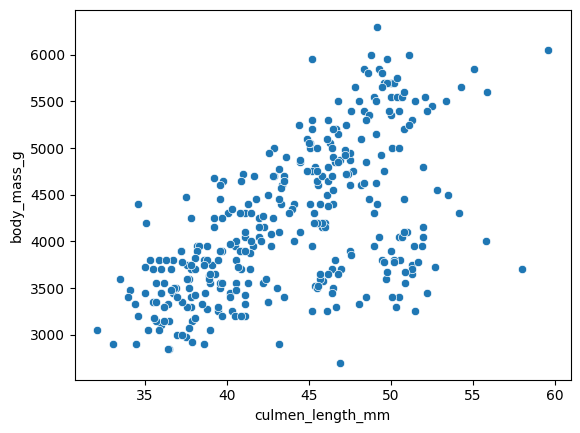

In [395]:
sns.scatterplot(data = penguins_data, x= penguins_data["culmen_length_mm"], y= penguins_data['body_mass_g'])

### 2. Advanced

Text(0.5, 1.0, 'Bivariate analysis of Culmen Length and body mass')

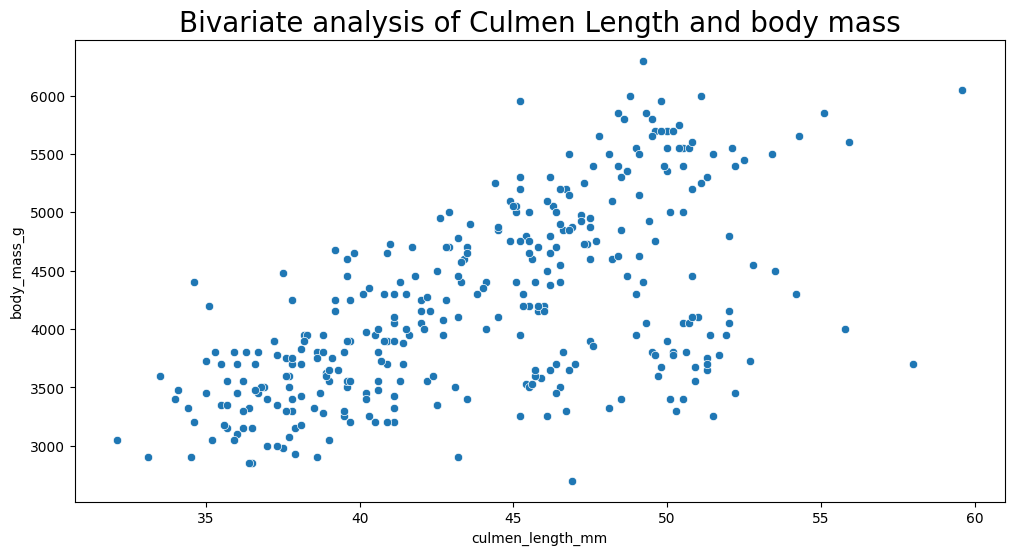

In [396]:
plt.figure(figsize= (12,6))
ax = sns.scatterplot(data = penguins_data, x= penguins_data["culmen_length_mm"], y= penguins_data['body_mass_g'])
ax.set_title('Bivariate analysis of Culmen Length and body mass', fontsize= 20)

### Nhận xét:
Biểu đồ tán xạ (Scatter plot) thể hiện mối tương quan thuận giữa độ dài mỏ (culmen_length_mm) và khối lượng cơ thể (body_mass_g)


## III. PHÂN TÍCH 2 BIẾN SỬ DỤNG PIVOT_TABLE

In [397]:
pd.pivot_table(penguins_data, values='culmen_length_mm', index='species', aggfunc=np.mean)

,culmen_length_mm
species,
Adelie,38.791391
Chinstrap,48.833824
Gentoo,47.504878


### Nhận xét:
Bảng Pivot table tính giá trị trung bình độ dài mỏ (culmen_length_mm) đại diện cho từng loài chim cánh cụt.

## IV.PHÂN TÍCH 2 BIẾN SỬ DỤNG PAIRPLOT

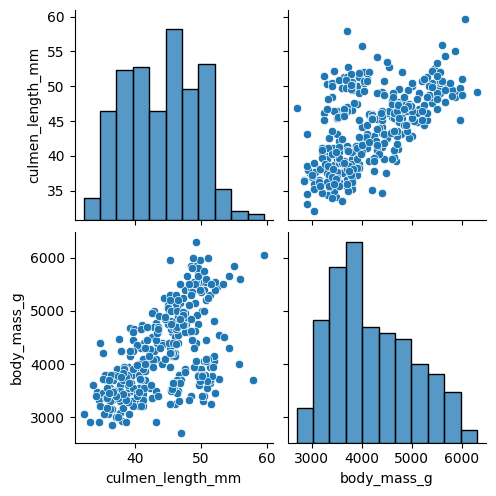

In [398]:
import seaborn as sns

sns.pairplot(data = penguins_data)

### Nhận xét: 
Ma trận biểu đồ pairplot trực quan hóa đồng thời phân bố đơn biến và đồ thị tương quan hai biến giữa các thuộc tính số

#  1.3.2. BÀI TOÁN 3 (NHIỆM VỤ 1)

## I. Sử dụng pandas profiling (ydata_profiling) trên dữ liệu Customer Personality Analysis


### 1. Nạp thư viện & dữ liệu

In [399]:
import pandas as pd
from ydata_profiling import ProfileReport

marketing_data = pd.read_csv("/kaggle/input/datasets/ngochancao/mkt-cp/marketing_campaign (2).csv")

### 2. Use the to_file method to output the report to an HTML file


In [400]:
profile = ProfileReport(marketing_data)
profile.to_file("profile_output.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 1/1 [00:00<00:00, 11.84it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

### Nhận xét: 
Công cụ ydata_profiling tự động tạo báo cáo tổng hợp chi tiết (Overview, Variables, Interactions, Correlations, Missing values) và xuất ra tập tin profile_output.html

#  1.3.2. BÀI TOÁN 3 (NHIỆM VỤ 2)

## I. Sử dụng dtale trên dữ liệu Marketing Campaign

### 1. Nạp thư viện & dữ liệu 

In [402]:
!pip install -q zstandard dtale

import pandas as pd
import dtale

marketing_data = pd.read_csv("/kaggle/input/datasets/ngochancao/mkt-cp/marketing_campaign (2).csv")

^C
ERROR: Operation cancelled by user


ImportError: cannot import name 'zstd' from 'backports' (/usr/local/lib/python3.13/dist-packages/setuptools/_vendor/backports/__init__.py)

### 2. Khởi chạy giao diện tương tác D-Tale trên trình duyệt


In [ ]:
dtale.show(marketing_data)